In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Paths
RAW_CMAPSS   = Path("../data/raw/cmapss")
RAW_WIND     = Path("../data/raw/edp_wind")
PROCESSED    = Path("../data/processed")
PROCESSED.mkdir(exist_ok=True)

print("✅ Imports OK")

✅ Imports OK


In [2]:
# CMAPSS column names — 21 sensors + 3 operational settings
CMAPSS_COLS = (
    ["unit_id", "cycle", "op_set_1", "op_set_2", "op_set_3"] +
    [f"sensor_{i}" for i in range(1, 22)]
)

def load_cmapss(subset="FD001"):
    """Load train/test split for one CMAPSS subset."""
    train = pd.read_csv(
        RAW_CMAPSS / f"train_{subset}.txt",
        sep=r"\s+", header=None, names=CMAPSS_COLS
    )
    test = pd.read_csv(
        RAW_CMAPSS / f"test_{subset}.txt",
        sep=r"\s+", header=None, names=CMAPSS_COLS
    )
    rul_test = pd.read_csv(
        RAW_CMAPSS / f"RUL_{subset}.txt",
        sep=r"\s+", header=None, names=["RUL"]
    )
    return train, test, rul_test

# Load FD001 (single fault mode — best for starting)
train_df, test_df, rul_test = load_cmapss("FD001")

print(f"Train shape : {train_df.shape}")
print(f"Test shape  : {test_df.shape}")
print(f"RUL test    : {rul_test.shape}")
train_df.head(3)

Train shape : (20631, 26)
Test shape  : (13096, 26)
RUL test    : (100, 1)


,unit_id,cycle,op_set_1,op_set_2,op_set_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


In [3]:
print("=== CMAPSS FD001 Overview ===")
print(f"Total units (engines) in train : {train_df['unit_id'].nunique()}")
print(f"Total units in test            : {test_df['unit_id'].nunique()}")
print(f"Cycle range                    : {train_df['cycle'].min()} → {train_df['cycle'].max()}")
print(f"\nMissing values: {train_df.isnull().sum().sum()}")

print("\n=== Sensor Stats (Train) ===")
train_df[[f"sensor_{i}" for i in range(1,22)]].describe().round(3)

=== CMAPSS FD001 Overview ===
Total units (engines) in train : 100
Total units in test            : 100
Cycle range                    : 1 → 362

Missing values: 0

=== Sensor Stats (Train) ===


,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.00,20631.000,20631.000,20631.000,20631.00,20631.000,20631.000,20631.000,20631.000,20631.0,...,20631.000,20631.000,20631.000,20631.000,20631.00,20631.000,20631.0,20631.0,20631.000,20631.000
mean,518.67,642.681,1590.523,1408.934,14.62,21.610,553.368,2388.097,9065.243,1.3,...,521.413,2388.096,8143.753,8.442,0.03,393.211,2388.0,100.0,38.816,23.290
std,0.00,0.500,6.131,9.001,0.00,0.001,0.885,0.071,22.083,0.0,...,0.738,0.072,19.076,0.038,0.00,1.549,0.0,0.0,0.181,0.108
min,518.67,641.210,1571.040,1382.250,14.62,21.600,549.850,2387.900,9021.730,1.3,...,518.690,2387.880,8099.940,8.325,0.03,388.000,2388.0,100.0,38.140,22.894
25%,518.67,642.325,1586.260,1402.360,14.62,21.610,552.810,2388.050,9053.100,1.3,...,520.960,2388.040,8133.245,8.415,0.03,392.000,2388.0,100.0,38.700,23.222
50%,518.67,642.640,1590.100,1408.040,14.62,21.610,553.440,2388.090,9060.660,1.3,...,521.480,2388.090,8140.540,8.439,0.03,393.000,2388.0,100.0,38.830,23.298
75%,518.67,643.000,1594.380,1414.555,14.62,21.610,554.010,2388.140,9069.420,1.3,...,521.950,2388.140,8148.310,8.466,0.03,394.000,2388.0,100.0,38.950,23.367
max,518.67,644.530,1616.910,1441.490,14.62,21.610,556.060,2388.560,9244.590,1.3,...,523.380,2388.560,8293.720,8.585,0.03,400.000,2388.0,100.0,39.430,23.618


In [4]:
def add_rul_labels(df, rul_clip=125):
    """
    Calculate Remaining Useful Life for each row.
    RUL = max_cycle_for_that_unit - current_cycle
    Clipped at rul_clip (piecewise linear — standard CMAPSS practice).
    """
    # Max cycle per engine = failure point
    max_cycles = df.groupby("unit_id")["cycle"].max().reset_index()
    max_cycles.columns = ["unit_id", "max_cycle"]
    
    df = df.merge(max_cycles, on="unit_id")
    df["RUL"] = df["max_cycle"] - df["cycle"]
    
    # Clip RUL — engines far from failure treated equally (standard benchmark)
    df["RUL"] = df["RUL"].clip(upper=rul_clip)
    df.drop(columns=["max_cycle"], inplace=True)
    
    return df

train_df = add_rul_labels(train_df, rul_clip=125)

print("RUL column added.")
print(f"RUL range: {train_df['RUL'].min()} → {train_df['RUL'].max()}")
print(train_df[["unit_id", "cycle", "RUL"]].head(8))

RUL column added.
RUL range: 0 → 125
   unit_id  cycle  RUL
0        1      1  125
1        1      2  125
2        1      3  125
3        1      4  125
4        1      5  125
5        1      6  125
6        1      7  125
7        1      8  125


In [5]:
def add_anomaly_labels(df, warning_threshold=30):
    """
    Binary anomaly label:
    0 = healthy (RUL > threshold)
    1 = degraded / anomalous (RUL <= threshold)
    """
    df["anomaly"] = (df["RUL"] <= warning_threshold).astype(int)
    return df

train_df = add_anomaly_labels(train_df, warning_threshold=30)

healthy  = (train_df["anomaly"] == 0).sum()
degraded = (train_df["anomaly"] == 1).sum()
print(f"Healthy samples  : {healthy}  ({100*healthy/len(train_df):.1f}%)")
print(f"Degraded samples : {degraded} ({100*degraded/len(train_df):.1f}%)")

Healthy samples  : 17531  (85.0%)
Degraded samples : 3100 (15.0%)


In [6]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

# Sensors with near-zero standard deviation carry no information
std_vals = train_df[sensor_cols].std()
USELESS_SENSORS = std_vals[std_vals < 0.01].index.tolist()
USEFUL_SENSORS  = std_vals[std_vals >= 0.01].index.tolist()

print(f"Useless sensors (removed) : {USELESS_SENSORS}")
print(f"Useful sensors  (kept)    : {USEFUL_SENSORS}")
print(f"Count: {len(USEFUL_SENSORS)} sensors retained")

Useless sensors (removed) : ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Useful sensors  (kept)    : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Count: 14 sensors retained


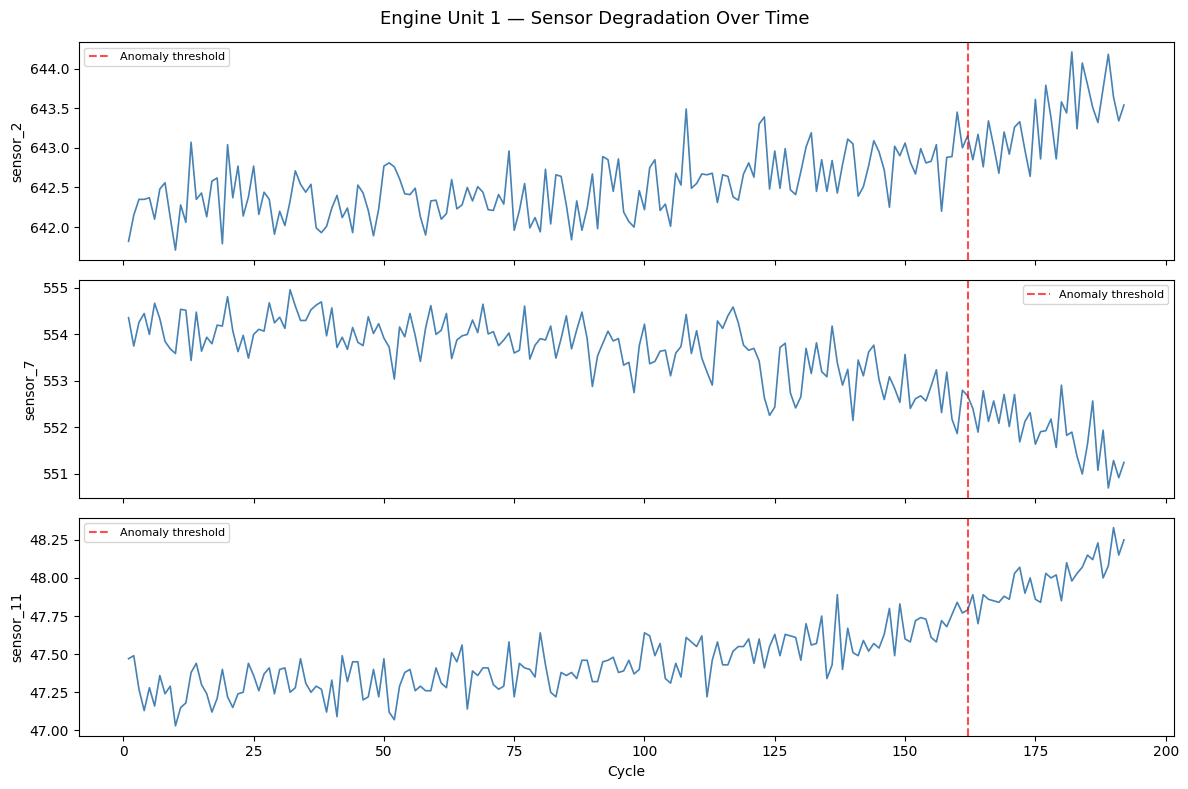

✅ Saved: outputs/reports/sensor_degradation.png


In [7]:
# Plot 3 sensors for one engine to visualize degradation pattern
unit = 1
unit_data = train_df[train_df["unit_id"] == unit]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
plot_sensors = ["sensor_2", "sensor_7", "sensor_11"]

for ax, sensor in zip(axes, plot_sensors):
    ax.plot(unit_data["cycle"], unit_data[sensor], color="steelblue", linewidth=1.2)
    ax.set_ylabel(sensor, fontsize=10)
    ax.axvline(
        x=unit_data["cycle"].max() - 30,
        color="red", linestyle="--", alpha=0.7, label="Anomaly threshold"
    )
    ax.legend(fontsize=8)

axes[-1].set_xlabel("Cycle")
fig.suptitle(f"Engine Unit {unit} — Sensor Degradation Over Time", fontsize=13)
plt.tight_layout()
plt.savefig("../outputs/reports/sensor_degradation.png", dpi=150)
plt.show()
print("✅ Saved: outputs/reports/sensor_degradation.png")

In [8]:
from sklearn.preprocessing import MinMaxScaler
import joblib

def normalize_cmapss(train_df, test_df, useful_sensors):
    """
    Fit scaler on train, transform both train and test.
    MinMax scaling: all sensors → [0, 1]
    """
    scaler = MinMaxScaler()
    
    train_scaled = train_df.copy()
    test_scaled  = test_df.copy()
    
    train_scaled[useful_sensors] = scaler.fit_transform(train_df[useful_sensors])
    test_scaled[useful_sensors]  = scaler.transform(test_df[useful_sensors])
    
    return train_scaled, test_scaled, scaler

# Add RUL + anomaly to test using ground truth RUL file
test_df = test_df.merge(
    test_df.groupby("unit_id")["cycle"].max().reset_index().rename(
        columns={"cycle": "max_cycle"}
    ), on="unit_id"
)

# For test set: use provided RUL file as true remaining life at last cycle
# Map ground truth RUL to each unit
rul_map = dict(zip(range(1, len(rul_test)+1), rul_test["RUL"]))
test_last = test_df[test_df["cycle"] == test_df["max_cycle"]].copy()
test_last["RUL"] = test_last["unit_id"].map(rul_map)
test_last["anomaly"] = (test_last["RUL"] <= 30).astype(int)
test_df.drop(columns=["max_cycle"], inplace=True)

train_scaled, test_scaled, scaler = normalize_cmapss(
    train_df, test_df, USEFUL_SENSORS
)

# Save scaler
joblib.dump(scaler, "../outputs/models/cmapss_scaler.pkl")
print("✅ Scaler saved: outputs/models/cmapss_scaler.pkl")
print(f"Train scaled shape: {train_scaled.shape}")

✅ Scaler saved: outputs/models/cmapss_scaler.pkl
Train scaled shape: (20631, 28)


In [9]:
def create_sequences(df, sensor_cols, window_size=30, target_col="RUL"):
    """
    Create overlapping sliding windows for LSTM input.
    Each sample = window_size cycles of sensor readings.
    Label = RUL at the last cycle of the window.
    """
    X, y = [], []
    
    for unit_id in df["unit_id"].unique():
        unit_data = df[df["unit_id"] == unit_id].sort_values("cycle")
        sensor_data = unit_data[sensor_cols].values
        target_data = unit_data[target_col].values
        
        # Slide window across all cycles
        for i in range(len(sensor_data) - window_size + 1):
            X.append(sensor_data[i : i + window_size])
            y.append(target_data[i + window_size - 1])
    
    return np.array(X), np.array(y)

WINDOW_SIZE = 30

X_seq, y_rul = create_sequences(
    train_scaled, USEFUL_SENSORS,
    window_size=WINDOW_SIZE, target_col="RUL"
)

# Anomaly labels for LSTM autoencoder
_, y_anomaly = create_sequences(
    train_scaled, USEFUL_SENSORS,
    window_size=WINDOW_SIZE, target_col="anomaly"
)

print(f"Sequence shape (X)     : {X_seq.shape}")
print(f"RUL labels shape (y)   : {y_rul.shape}")
print(f"Anomaly labels shape   : {y_anomaly.shape}")
print(f"Window = {WINDOW_SIZE} cycles × {len(USEFUL_SENSORS)} sensors")

Sequence shape (X)     : (17731, 30, 14)
RUL labels shape (y)   : (17731,)
Anomaly labels shape   : (17731,)
Window = 30 cycles × 14 sensors


In [10]:
from sklearn.model_selection import train_test_split

# Sequence split (for LSTM models)
X_train_seq, X_val_seq, y_train_rul, y_val_rul = train_test_split(
    X_seq, y_rul, test_size=0.2, random_state=42
)

_, _, y_train_anom, y_val_anom = train_test_split(
    X_seq, y_anomaly, test_size=0.2, random_state=42
)

# Flat split (for XGBoost — no sequences)
feature_cols = USEFUL_SENSORS + ["op_set_1", "op_set_2", "op_set_3", "cycle"]
X_flat = train_scaled[feature_cols].values
y_flat_rul = train_scaled["RUL"].values

X_train_flat, X_val_flat, y_train_flat, y_val_flat = train_test_split(
    X_flat, y_flat_rul, test_size=0.2, random_state=42
)

print("=== Split Summary ===")
print(f"LSTM  — Train: {X_train_seq.shape}, Val: {X_val_seq.shape}")
print(f"XGBoost — Train: {X_train_flat.shape}, Val: {X_val_flat.shape}")

=== Split Summary ===
LSTM  — Train: (14184, 30, 14), Val: (3547, 30, 14)
XGBoost — Train: (16504, 18), Val: (4127, 18)


In [11]:
# Save everything needed for model training
np.save("../data/processed/X_train_seq.npy",   X_train_seq)
np.save("../data/processed/X_val_seq.npy",     X_val_seq)
np.save("../data/processed/y_train_rul.npy",   y_train_rul)
np.save("../data/processed/y_val_rul.npy",     y_val_rul)
np.save("../data/processed/y_train_anom.npy",  y_train_anom)
np.save("../data/processed/y_val_anom.npy",    y_val_anom)

np.save("../data/processed/X_train_flat.npy",  X_train_flat)
np.save("../data/processed/X_val_flat.npy",    X_val_flat)
np.save("../data/processed/y_train_flat.npy",  y_train_flat)
np.save("../data/processed/y_val_flat.npy",    y_val_flat)

# Save full train dataframe
train_scaled.to_csv("../data/processed/train_cmapss_processed.csv", index=False)
test_scaled.to_csv("../data/processed/test_cmapss_processed.csv",   index=False)

# Save useful sensor list for reuse across all modules
import json
meta = {
    "useful_sensors": USEFUL_SENSORS,
    "useless_sensors": USELESS_SENSORS,
    "window_size": WINDOW_SIZE,
    "n_features": len(USEFUL_SENSORS),
    "rul_clip": 125,
    "anomaly_threshold": 30
}
with open("../data/processed/dataset_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("✅ All processed CMAPSS data saved to data/processed/")

✅ All processed CMAPSS data saved to data/processed/


In [12]:
import os

# Find the CSV file (name may vary)
wind_files = list(RAW_WIND.glob("*.csv"))
print(f"Files found: {wind_files}")

wind_df = pd.read_csv(wind_files[0], parse_dates=[0])
print(f"\nShape: {wind_df.shape}")
print(f"Columns: {list(wind_df.columns)}")
wind_df.head(3)

Files found: [WindowsPath('../data/raw/edp_wind/T1.csv')]

Shape: (50530, 5)
Columns: ['Date/Time', 'LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)']


,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789


In [13]:
# Standardize column names
wind_df.columns = [c.strip().lower().replace(" ", "_") for c in wind_df.columns]

print("Standardized columns:", list(wind_df.columns))
print(f"\nMissing values:\n{wind_df.isnull().sum()}")
print(f"\nDate range: {wind_df.iloc[:,0].min()} → {wind_df.iloc[:,0].max()}")

# Rename to standard names (adjust if your column names differ)
col_map = {}
for col in wind_df.columns:
    if "wind" in col and "speed" in col:
        col_map[col] = "wind_speed"
    elif "power" in col:
        col_map[col] = "active_power"
    elif "rotor" in col:
        col_map[col] = "rotor_rpm"
    elif "generator" in col:
        col_map[col] = "generator_rpm"
    elif "date" in col or "time" in col:
        col_map[col] = "timestamp"

wind_df.rename(columns=col_map, inplace=True)
print("\nRenamed columns:", list(wind_df.columns))

# Drop rows with all nulls
wind_df.dropna(how="all", inplace=True)

# Fill remaining nulls with forward fill
wind_df.fillna(method="ffill", inplace=True)
wind_df.fillna(method="bfill", inplace=True)

print(f"\nAfter cleaning — Shape: {wind_df.shape}")
print(f"Remaining nulls: {wind_df.isnull().sum().sum()}")

Standardized columns: ['date/time', 'lv_activepower_(kw)', 'wind_speed_(m/s)', 'theoretical_power_curve_(kwh)', 'wind_direction_(°)']

Missing values:
date/time                        0
lv_activepower_(kw)              0
wind_speed_(m/s)                 0
theoretical_power_curve_(kwh)    0
wind_direction_(°)               0
dtype: int64

Date range: 01 01 2018 00:00 → 31 12 2018 23:50

Renamed columns: ['timestamp', 'active_power', 'wind_speed', 'active_power', 'wind_direction_(°)']

After cleaning — Shape: (50530, 5)
Remaining nulls: 0


In [15]:
# Sort by time
if "timestamp" in wind_df.columns:
    wind_df = wind_df.sort_values("timestamp").reset_index(drop=True)

def get_series(df, col):
    """Return a single Series even if the dataframe contains duplicated columns."""
    data = df.loc[:, col]
    if isinstance(data, pd.DataFrame):
        data = data.iloc[:, 0]
    return data

# Add rolling statistics (10-sample window = ~10 minutes if 1min data)
for col in ["wind_speed", "active_power", "rotor_rpm"]:
    if col in wind_df.columns:
        series = get_series(wind_df, col)
        wind_df[f"{col}_rolling_mean"] = series.rolling(10, min_periods=1).mean()
        wind_df[f"{col}_rolling_std"]  = series.rolling(10, min_periods=1).std().fillna(0)

# Power coefficient (efficiency indicator)
if "wind_speed" in wind_df.columns and "active_power" in wind_df.columns:
    active_power = get_series(wind_df, "active_power")
    wind_speed = get_series(wind_df, "wind_speed")
    wind_df["power_ratio"] = (
        active_power / (wind_speed.clip(lower=0.1) ** 3)
    ).clip(upper=10)

print("Wind feature engineering done.")
print(f"Final shape: {wind_df.shape}")
wind_df.head(3)

Wind feature engineering done.
Final shape: (50530, 10)


,timestamp,active_power,wind_speed,active_power,wind_direction_(°),wind_speed_rolling_mean,wind_speed_rolling_std,active_power_rolling_mean,active_power_rolling_std,power_ratio
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904,5.311336,0.000000,380.047791,0.000000,2.536453
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113,5.491751,0.255146,416.908493,52.128905,2.486497
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789,5.399847,0.240602,380.064524,73.696306,2.158906


In [16]:
wind_df.to_csv("../data/processed/wind_scada_processed.csv", index=False)
print("✅ Saved: data/processed/wind_scada_processed.csv")

✅ Saved: data/processed/wind_scada_processed.csv


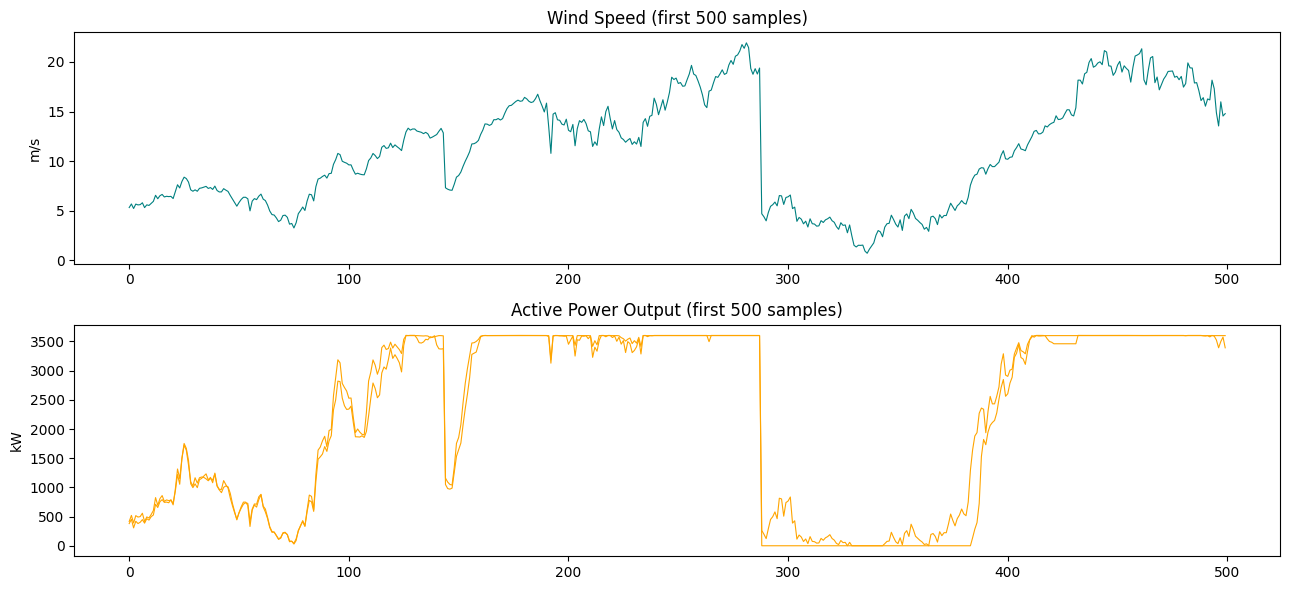

✅ Saved: outputs/reports/wind_scada_overview.png


In [17]:
if "wind_speed" in wind_df.columns and "active_power" in wind_df.columns:
    fig, axes = plt.subplots(2, 1, figsize=(13, 6))
    
    axes[0].plot(wind_df["wind_speed"].values[:500], color="teal", linewidth=0.8)
    axes[0].set_title("Wind Speed (first 500 samples)")
    axes[0].set_ylabel("m/s")
    
    axes[1].plot(wind_df["active_power"].values[:500], color="orange", linewidth=0.8)
    axes[1].set_title("Active Power Output (first 500 samples)")
    axes[1].set_ylabel("kW")
    
    plt.tight_layout()
    plt.savefig("../outputs/reports/wind_scada_overview.png", dpi=150)
    plt.show()
    print("✅ Saved: outputs/reports/wind_scada_overview.png")